# Five-fold cross-validation of the hybrid model (image + blood tests) with nested algorithm selection

**Purpose.** To confirm that the performance of the hybrid model does not depend on a particular train/test split or on the
choice of the machine-learning algorithm, the model is evaluated by five-fold cross-validation in which the algorithm is
selected and tuned within the training data of each fold only.

**Data.** 197 patients (100 with acute cholecystitis, 97 controls), one patient per row, split into five folds at the patient
level and stratified by diagnosis (`StratifiedKFold`, random seed 42; 39–40 test patients per fold). For each fold, EfficientNetB0
was fine-tuned on the training patients of that fold only and used to extract 128-dimensional image features (separate notebook).
The features of each fold are read from:
- `fold{k}_img_feature_128_with_blood.csv`: representative slice of every patient, with the 10 blood tests; `split` = train / test
- `all_slices/fold{k}_test_all_slices_img_feature_128_with_blood.csv`: all gallbladder slices of the test patients (hybrid masks)

**Procedure in each outer fold** (the test patients are not used in steps 1–3)
1. PCA (41 components) is fitted on the training patients and applied to the test patients.
2. Features: 10 blood tests + 41 image principal components, standardized using the training patients.
3. Inner five-fold stratified cross-validation on the training patients: `compare_models()` ranks the candidate algorithms
   (logistic regression, k-nearest neighbours, naive Bayes, decision tree, random forest, extra trees, gradient boosting,
   AdaBoost, linear discriminant analysis, LightGBM) by accuracy, and the top-ranked algorithm is tuned with
   `tune_model()` (15 random-search iterations, optimizing precision).
4. The tuned model predicts the test patients of the outer fold: (a) on the representative slice, and (b) on all slices,
   where a patient is classified as positive if any slice has a predicted probability ≥ 0.5.

**Reported results.** The algorithm selected in each fold with the inner cross-validation scores of all candidates; accuracy,
sensitivity, specificity, PPV, NPV, F1 and AUC per fold and pooled over all folds, with 95% confidence intervals
(Wilson score interval for proportions; stratified bootstrap with 2,000 resamples for AUC and F1) and the mean ± SD across folds;
confusion matrices and ROC curves.

In [1]:
# Run once in the local environment (PyCaret 3.3 requires Python 3.9-3.11):
# pip install pycaret

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score
from scipy import stats
from pycaret.classification import setup, compare_models, tune_model, predict_model, pull

In [3]:
BASE = "./cv5_balanced_197_20261022"   # output of the feature-extraction notebook (per-fold CSV files)
ALL_SLICES_DIR = f"{BASE}/all_slices"
OUT_DIR = f"{BASE}/results_nested_model_selection_hybrid"
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
N_FOLDS = 5
N_PCA = 41
THRESHOLD = 0.5
N_BOOT = 2000

# Pre-specified settings for the inner loop
SELECT_METRIC = "Accuracy"      # ranking of the algorithms in compare_models
TUNE_METRIC = "Precision"   # hyperparameter tuning of the selected algorithm
MODEL_CANDIDATES = ["lr", "knn", "nb", "dt", "rf", "et", "gbc", "ada", "lda", "lightgbm"]

clinical_cols = ["WBC", "PLT", "CRP", "T-Bil", "AST", "ALT", "γGTP", "ALP", "Cre", "PT-INR"]
pca_cols = [f"img_pca_{i}" for i in range(N_PCA)]

## Nested cross-validation

In [4]:
# ===== Functions for metrics and 95% confidence intervals =====
# Proportion metrics use the Wilson score interval; AUC and F1 use a stratified bootstrap (percentile method).
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

def bootstrap_ci(y_true, y_prob, stat_fn, n_boot=N_BOOT, seed=SEED):
    # Resample within each class so that every bootstrap sample contains both positives and negatives
    rng = np.random.default_rng(seed)
    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)])
        vals.append(stat_fn(y_true[idx], y_prob[idx]))
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

def compute_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    f1_fn = lambda yt, yp: f1_score(yt, (yp >= threshold).astype(int), zero_division=0)
    rows = [
        ("AUC", roc_auc_score(y_true, y_prob), *bootstrap_ci(y_true, y_prob, roc_auc_score)),
        ("accuracy", (tp + tn) / len(y_true), *wilson_ci(tp + tn, len(y_true))),
        ("sensitivity", tp / (tp + fn), *wilson_ci(tp, tp + fn)),
        ("specificity", tn / (tn + fp), *wilson_ci(tn, tn + fp)),
        ("PPV", tp / (tp + fp) if tp + fp > 0 else np.nan, *wilson_ci(tp, tp + fp)),
        ("NPV", tn / (tn + fn) if tn + fn > 0 else np.nan, *wilson_ci(tn, tn + fn)),
        ("F1", f1_fn(y_true, y_prob), *bootstrap_ci(y_true, y_prob, f1_fn)),
    ]
    df = pd.DataFrame(rows, columns=["metric", "value", "ci_low", "ci_high"])
    counts = {"n": len(y_true), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return df, counts

def fmt_ci(r):
    return f"{r['value']:.3f} ({r['ci_low']:.3f}-{r['ci_high']:.3f})"

In [5]:
# ===== Nested CV: in each outer fold, choose the algorithm on the training data only → tune → predict the test set =====
def to_X(x, pca):
    # Same column layout as the original train_X (10 blood test columns + 41 img_pca columns + label_x)
    return pd.concat(
        [
            x[clinical_cols].reset_index(drop=True),
            pd.DataFrame(pca.transform(x[img_cols]), columns=pca_cols),
            x[["label_x"]].reset_index(drop=True),
        ],
        axis=1,
    )

single_preds, slice_preds, compare_tables, selected = [], [], [], []

for k in range(1, N_FOLDS + 1):
    print(f"\n========== outer fold {k} ==========")
    d = pd.read_csv(f"{BASE}/fold{k}_img_feature_128_with_blood.csv")
    te_all = pd.read_csv(f"{ALL_SLICES_DIR}/fold{k}_test_all_slices_img_feature_128_with_blood.csv")
    img_cols = [c for c in d.columns if c.startswith("img_feat_")]

    tr = d[d["split"] == "train"].reset_index(drop=True)
    te = d[d["split"] == "test"].reset_index(drop=True)
    assert not (set(tr["patient_id"]) & set(te["patient_id"])), "Patient leakage!"
    assert set(te_all["patient_id"]) <= set(te["patient_id"])

    # Fit PCA on train only (the test set is never used)
    pca = PCA(n_components=N_PCA, random_state=SEED).fit(tr[img_cols])
    train_X, test_X, slices_X = to_X(tr, pca), to_X(te, pca), to_X(te_all, pca)

    # The inner CV (fold=5) runs on train_X only; test_data is only the holdout for predict_model
    setup(
        data=train_X,
        target="label_x",
        test_data=test_X,
        fold_strategy="stratifiedkfold",
        fold=5,
        session_id=SEED,
        normalize=True,
        index=False,  # train_X/test_X both have 0-based indices, so let PyCaret reset the index
        verbose=False,
    )

    # 1) Choose the algorithm by the inner CV
    best = compare_models(include=MODEL_CANDIDATES, sort=SELECT_METRIC, n_select=1, verbose=False)
    table = pull().copy()
    best_id = table.index[0]
    compare_tables.append(table.reset_index().rename(columns={"index": "model_id"}).assign(fold=k))

    # 2) Tune the selected algorithm (inner CV again)
    tuned_model = tune_model(best, n_iter=15, optimize=TUNE_METRIC, verbose=False)
    selected.append({
        "fold": k, "model_id": best_id, "model": table.loc[best_id, "Model"],
        f"inner_{SELECT_METRIC}": table.loc[best_id, SELECT_METRIC],
    })
    print(f"selected: {best_id} ({table.loc[best_id, 'Model']}), inner {SELECT_METRIC} = {table.loc[best_id, SELECT_METRIC]:.3f}")

    # 3) Predict the outer test patients
    pred = predict_model(tuned_model, data=test_X, raw_score=True, verbose=False)
    single_preds.append(pd.DataFrame({
        "fold": k, "model_id": best_id, "patient_id": te["patient_id"].values,
        "label_x": te["label_x"].values, "prob": pred["prediction_score_1"].values,
    }))

    pred_all = predict_model(tuned_model, data=slices_X, raw_score=True, verbose=False)
    slice_preds.append(pd.DataFrame({
        "fold": k, "model_id": best_id, "patient_id": te_all["patient_id"].values, "z": te_all["z"].values,
        "mask_source": te_all["mask_source"].values, "path": te_all["path"].values,
        "label_x": te_all["label_x"].values, "prob": pred_all["prediction_score_1"].values,
    }))

    print(f"outer fold {k}: single-image AUC = {roc_auc_score(te['label_x'], pred['prediction_score_1']):.3f}")

df_single = pd.concat(single_preds, ignore_index=True)
df_slices = pd.concat(slice_preds, ignore_index=True)
df_compare = pd.concat(compare_tables, ignore_index=True)
df_selected = pd.DataFrame(selected)

df_single.to_csv(f"{OUT_DIR}/single_image_pred.csv", index=False)
df_slices.to_csv(f"{OUT_DIR}/all_slices_pred.csv", index=False)
df_compare.to_csv(f"{OUT_DIR}/inner_cv_compare_models_per_fold.csv", index=False)
df_selected.to_csv(f"{OUT_DIR}/selected_model_per_fold.csv", index=False)


========== outer fold 1 ==========
selected: lightgbm (Light Gradient Boosting Machine), inner Accuracy = 0.962
outer fold 1: single-image AUC = 0.987

========== outer fold 2 ==========
selected: rf (Random Forest Classifier), inner Accuracy = 0.968
outer fold 2: single-image AUC = 0.958

========== outer fold 3 ==========
selected: rf (Random Forest Classifier), inner Accuracy = 0.931
outer fold 3: single-image AUC = 0.997

========== outer fold 4 ==========
selected: et (Extra Trees Classifier), inner Accuracy = 0.943
outer fold 4: single-image AUC = 1.000

========== outer fold 5 ==========
selected: et (Extra Trees Classifier), inner Accuracy = 0.949
outer fold 5: single-image AUC = 0.966


In [6]:
# ===== Which algorithm was selected, and how each candidate scored in the inner CV =====
print("Selected algorithm per outer fold:")
print(df_selected.to_string(index=False))
print()
print("Selection frequency:")
print(df_selected["model"].value_counts())
print()

metric_cols = ["Accuracy", "AUC", "Recall", "Prec.", "F1"]
inner_summary = (
    df_compare.groupby(["model_id", "Model"])[metric_cols]
    .agg(["mean", "std"])
    .sort_values((SELECT_METRIC, "mean"), ascending=False)
)
inner_summary.to_csv(f"{OUT_DIR}/inner_cv_compare_models_summary.csv")
print(f"Inner-CV scores of every candidate (mean ± SD over the 5 outer folds), sorted by {SELECT_METRIC}:")
inner_summary.round(3)

Selected algorithm per outer fold:
 fold model_id                           model  inner_Accuracy
    1 lightgbm Light Gradient Boosting Machine          0.9617
    2       rf        Random Forest Classifier          0.9681
    3       rf        Random Forest Classifier          0.9306
    4       et          Extra Trees Classifier          0.9431
    5       et          Extra Trees Classifier          0.9494

Selection frequency:
model
Random Forest Classifier           2
Extra Trees Classifier             2
Light Gradient Boosting Machine    1
Name: count, dtype: int64

Inner-CV scores of every candidate (mean ± SD over the 5 outer folds), sorted by Accuracy:


                                         Accuracy           AUC        Recall  \
                                             mean    std   mean    std   mean   
model_id Model                                                                  
rf       Random Forest Classifier           0.947  0.017  0.983  0.008  0.930   
et       Extra Trees Classifier             0.946  0.017  0.984  0.007  0.932   
lightgbm Light Gradient Boosting Machine    0.935  0.022  0.979  0.009  0.925   
ada      Ada Boost Classifier               0.918  0.024  0.974  0.013  0.910   
lr       Logistic Regression                0.909  0.024  0.965  0.018  0.878   
gbc      Gradient Boosting Classifier       0.906  0.022  0.960  0.003  0.903   
nb       Naive Bayes                        0.895  0.019  0.955  0.012  0.847   
dt       Decision Tree Classifier           0.881  0.037  0.881  0.036  0.872   
lda      Linear Discriminant Analysis       0.866  0.032  0.943  0.024  0.820   
knn      K Neighbors Classif

In [7]:
# ===== Aggregate all-slice predictions to the patient level =====
# max_prob >= 0.5 is "positive if any slice is positive"; positive_rate >= 0.5 is majority vote (for reference).
df_patient = (
    df_slices.assign(is_positive=(df_slices["prob"] >= THRESHOLD))
    .groupby("patient_id")
    .agg(
        fold=("fold", "first"), label_x=("label_x", "first"), mask_source=("mask_source", "first"),
        n_slices=("prob", "size"), max_prob=("prob", "max"), positive_rate=("is_positive", "mean"),
    )
    .reset_index()
)
df_patient.to_csv(f"{OUT_DIR}/all_slices_patient_level_pred.csv", index=False)
print("patients:", len(df_patient))
print(df_patient.groupby(["fold", "label_x"]).size().unstack(fill_value=0))

patients: 195
label_x   0   1
fold           
1        20  19
2        19  20
3        19  20
4        19  20
5        19  20


In [8]:
# ===== Metrics per fold and pooled over all folds, and summary across folds =====
def evaluate(df, score_col, prefix):
    folds = sorted(df["fold"].unique())
    metric_tables, cm_rows = [], []
    for k in folds + ["pooled"]:
        d = df if k == "pooled" else df[df["fold"] == k]
        m, counts = compute_metrics(d["label_x"].values, d[score_col].values)
        m.insert(0, "fold", k)
        metric_tables.append(m)
        cm_rows.append({"fold": k, **counts})

    df_metrics = pd.concat(metric_tables, ignore_index=True)
    df_metrics["value_95ci"] = df_metrics.apply(fmt_ci, axis=1)
    df_cm = pd.DataFrame(cm_rows)

    per_fold = df_metrics[df_metrics["fold"] != "pooled"]
    t_crit = stats.t.ppf(0.975, df=len(folds) - 1)
    summary_rows = []
    for metric, g in per_fold.groupby("metric", sort=False):
        mean, sd = g["value"].mean(), g["value"].std(ddof=1)
        half = t_crit * sd / np.sqrt(len(g))
        summary_rows.append({
            "metric": metric, "mean": mean, "sd": sd, "ci_low": mean - half, "ci_high": mean + half,
            "mean_sd": f"{mean:.3f} ± {sd:.3f}",
            "mean_95ci": f"{mean:.3f} ({mean - half:.3f}-{mean + half:.3f})",
        })
    df_summary = pd.DataFrame(summary_rows)

    df_metrics.to_csv(f"{OUT_DIR}/{prefix}_metrics_per_fold.csv", index=False)
    df_cm.to_csv(f"{OUT_DIR}/{prefix}_confusion_matrix_per_fold.csv", index=False)
    df_summary.to_csv(f"{OUT_DIR}/{prefix}_metrics_summary.csv", index=False)

    print(f"===== {prefix} =====")
    print(df_cm.to_string(index=False))
    print()
    print(df_metrics.pivot(index="fold", columns="metric", values="value_95ci")
          [["AUC", "accuracy", "sensitivity", "specificity", "PPV", "NPV", "F1"]].to_string())
    print()
    print(df_summary[["metric", "mean_sd", "mean_95ci"]].to_string(index=False))
    print()
    return df_cm

# Performance of the whole procedure (algorithm selection + tuning + prediction)
cm_single = evaluate(df_single, "prob", "single_image")
cm_any = evaluate(df_patient, "max_prob", "all_slices_any_positive")
cm_major = evaluate(df_patient, "positive_rate", "all_slices_majority")

===== single_image =====
  fold   n  TN  FP  FN  TP
     1  40  18   2   1  19
     2  40  18   2   2  18
     3  39  18   1   0  20
     4  39  19   0   0  20
     5  39  19   0   3  17
pooled 197  92   5   6  94

metric                  AUC             accuracy          sensitivity          specificity                  PPV                  NPV                   F1
fold                                                                                                                                                     
1       0.987 (0.958-1.000)  0.925 (0.801-0.974)  0.950 (0.764-0.991)  0.900 (0.699-0.972)  0.905 (0.711-0.973)  0.947 (0.754-0.991)  0.927 (0.842-1.000)
2       0.958 (0.887-1.000)  0.900 (0.769-0.960)  0.900 (0.699-0.972)  0.900 (0.699-0.972)  0.900 (0.699-0.972)  0.900 (0.699-0.972)  0.900 (0.800-0.976)
3       0.997 (0.984-1.000)  0.974 (0.868-0.995)  1.000 (0.839-1.000)  0.947 (0.754-0.991)  0.952 (0.773-0.992)  1.000 (0.824-1.000)  0.976 (0.930-1.000)
4       1.000 (

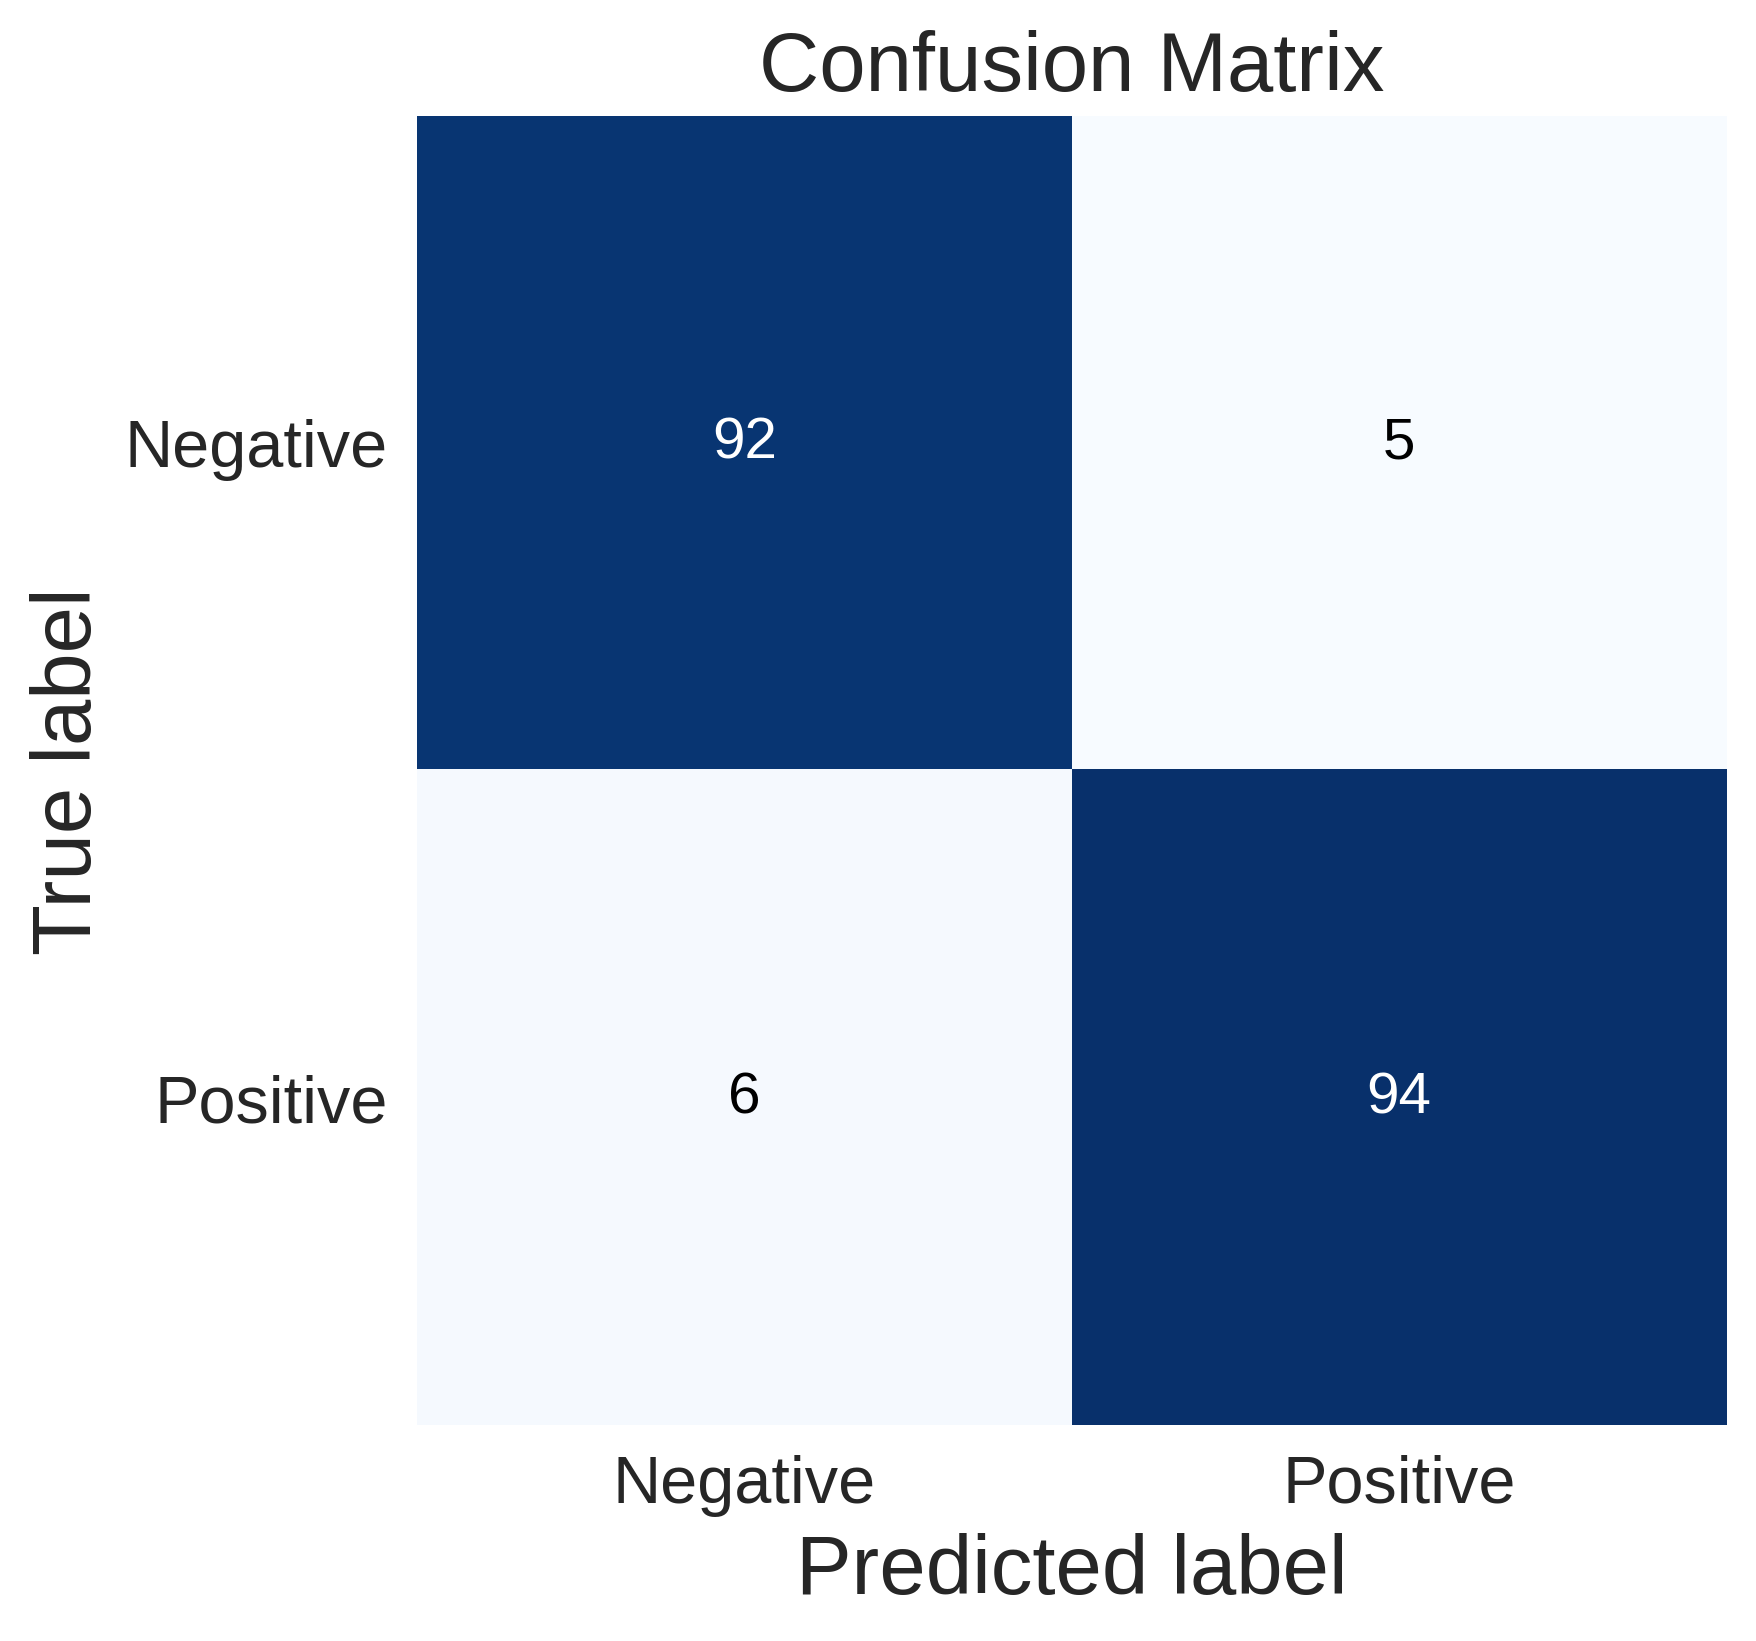

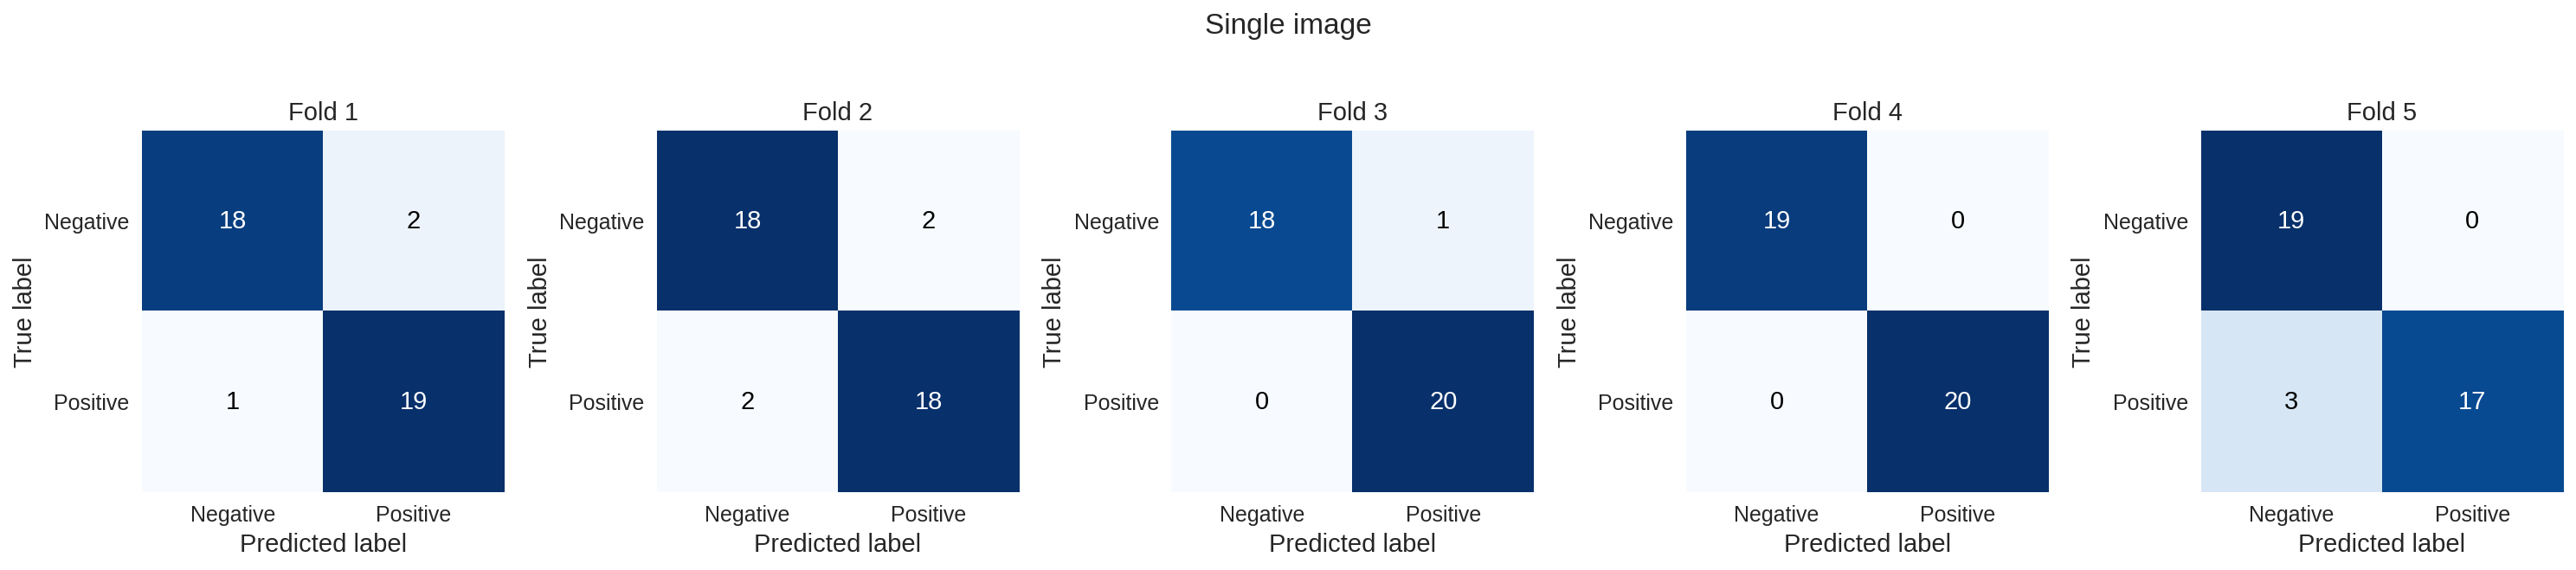

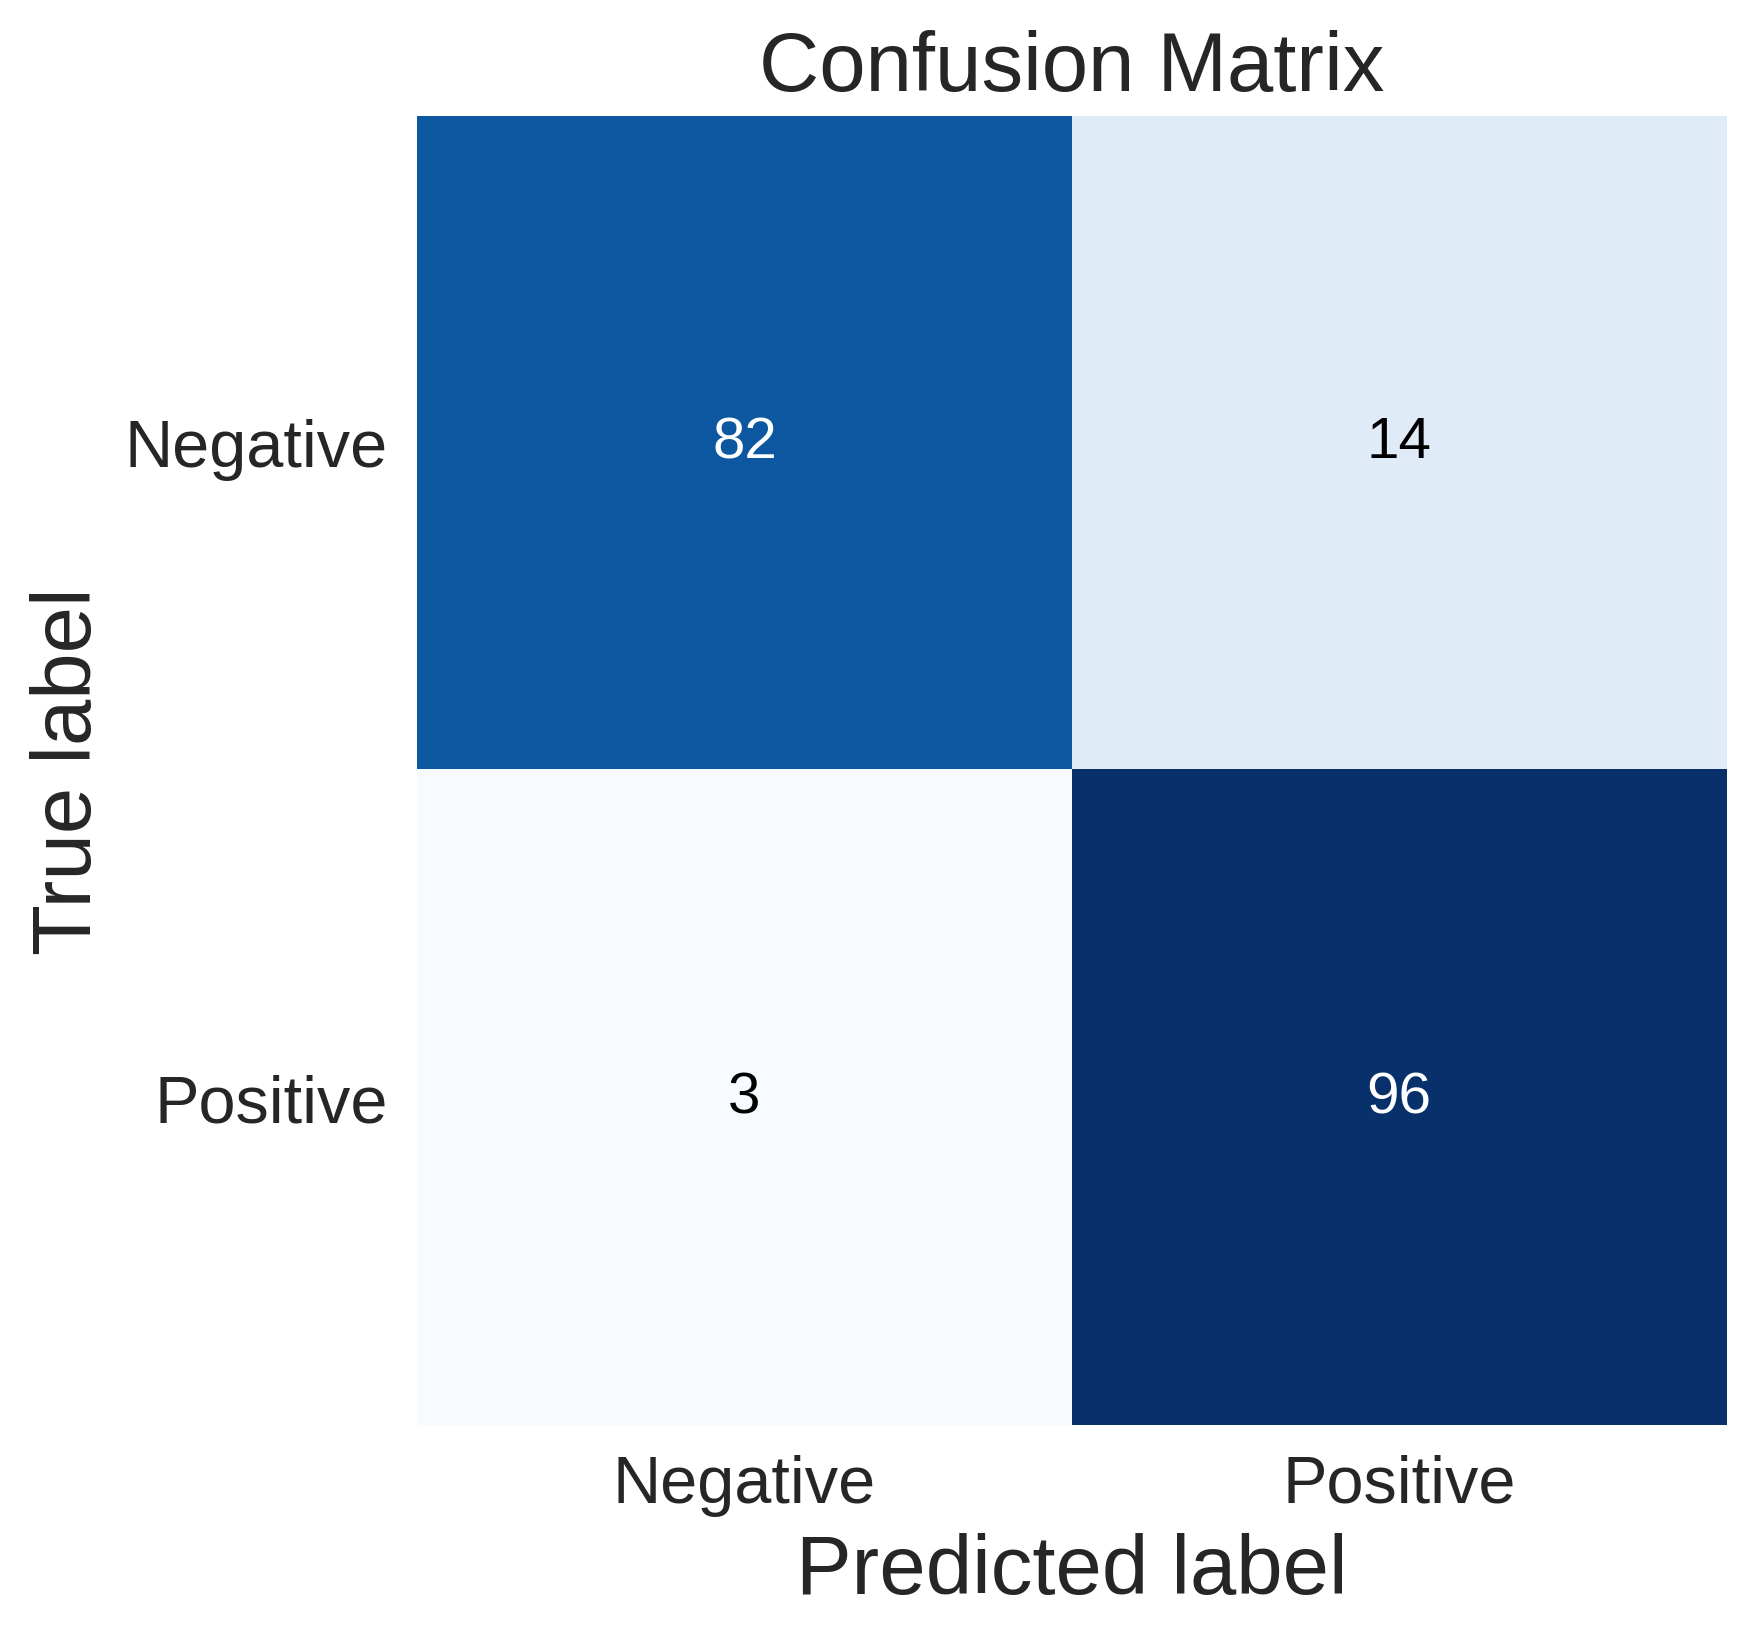

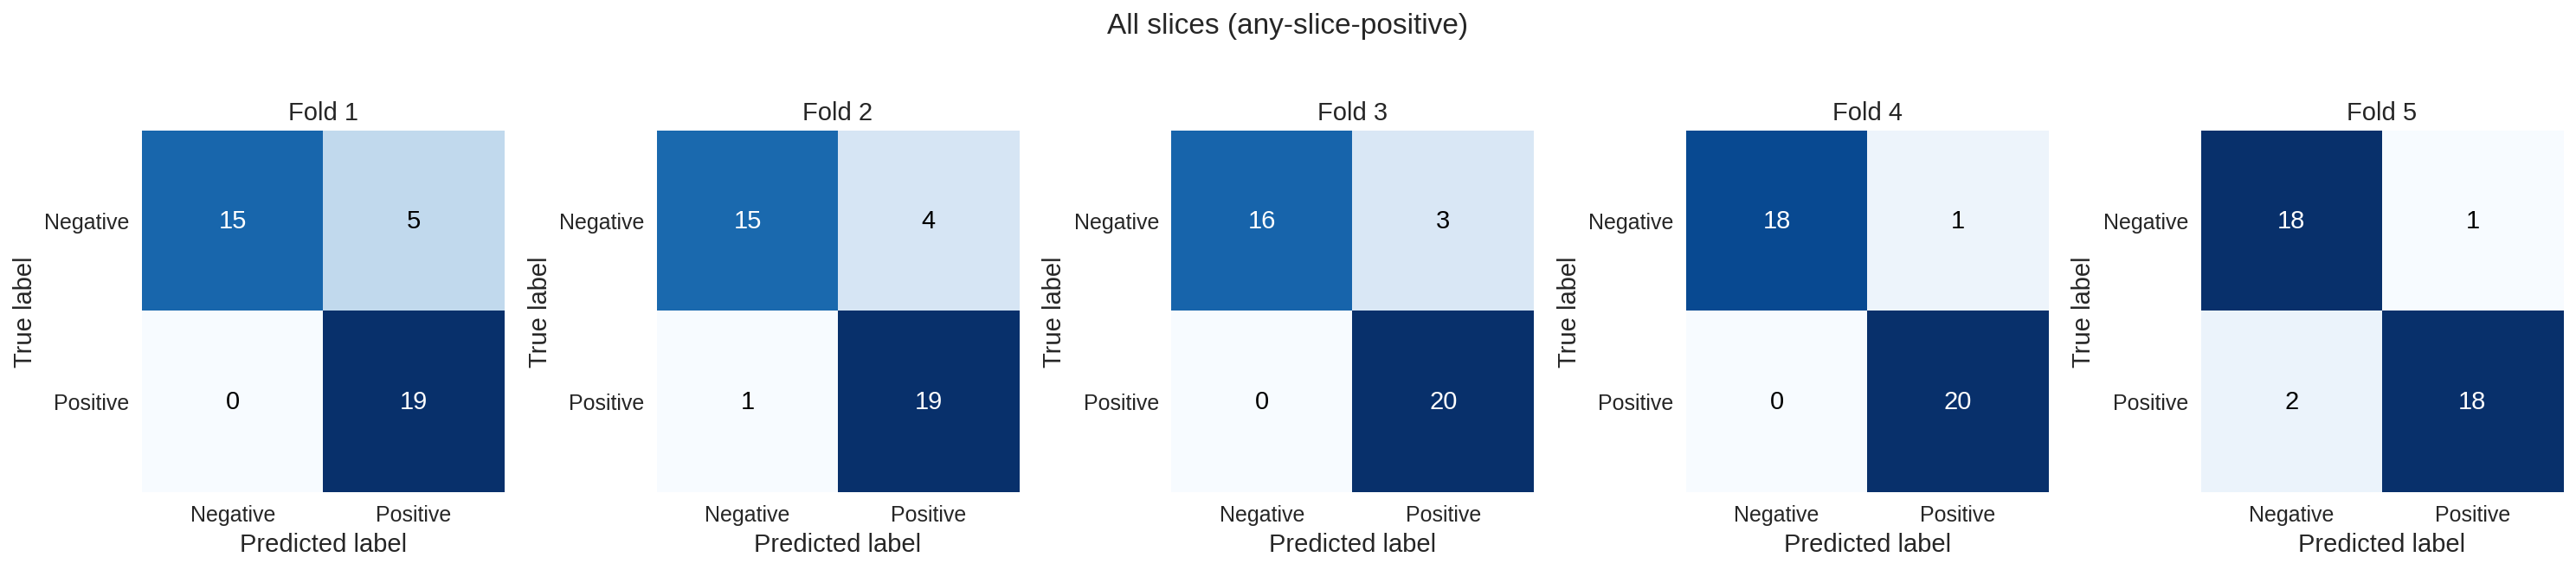

In [9]:
# ===== Confusion matrices: pooled over all folds (for the main figure) + per fold (for the supplementary material) =====
def plot_cm(ax, cm, title, label_size=16, axis_size=20, text_size=14):
    # Same style as the original cell 30
    ax.imshow(cm, cmap=plt.cm.Blues)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=text_size)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Negative", "Positive"], fontsize=label_size)
    ax.set_yticklabels(["Negative", "Positive"], fontsize=label_size)
    ax.set_xlabel("Predicted label", fontsize=axis_size)
    ax.set_ylabel("True label", fontsize=axis_size)
    ax.set_title(title, fontsize=axis_size)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

def cm_array(r):
    return np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])

for df_cm, prefix, title in [
    (cm_single, "single_image", "Single image"),
    (cm_any, "all_slices_any_positive", "All slices (any-slice-positive)"),
]:
    # Pooled over all folds
    fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
    plot_cm(ax, cm_array(df_cm[df_cm["fold"] == "pooled"].iloc[0]), "Confusion Matrix")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{prefix}_confusion_matrix_pooled.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Per fold
    per_fold = df_cm[df_cm["fold"] != "pooled"]
    fig, axes = plt.subplots(1, len(per_fold), figsize=(4 * len(per_fold), 4.5), dpi=150)
    for ax, (_, r) in zip(axes, per_fold.iterrows()):
        plot_cm(ax, cm_array(r), f"Fold {r['fold']}", label_size=12, axis_size=14)
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{prefix}_confusion_matrix_per_fold.png", dpi=300, bbox_inches="tight")
    plt.show()

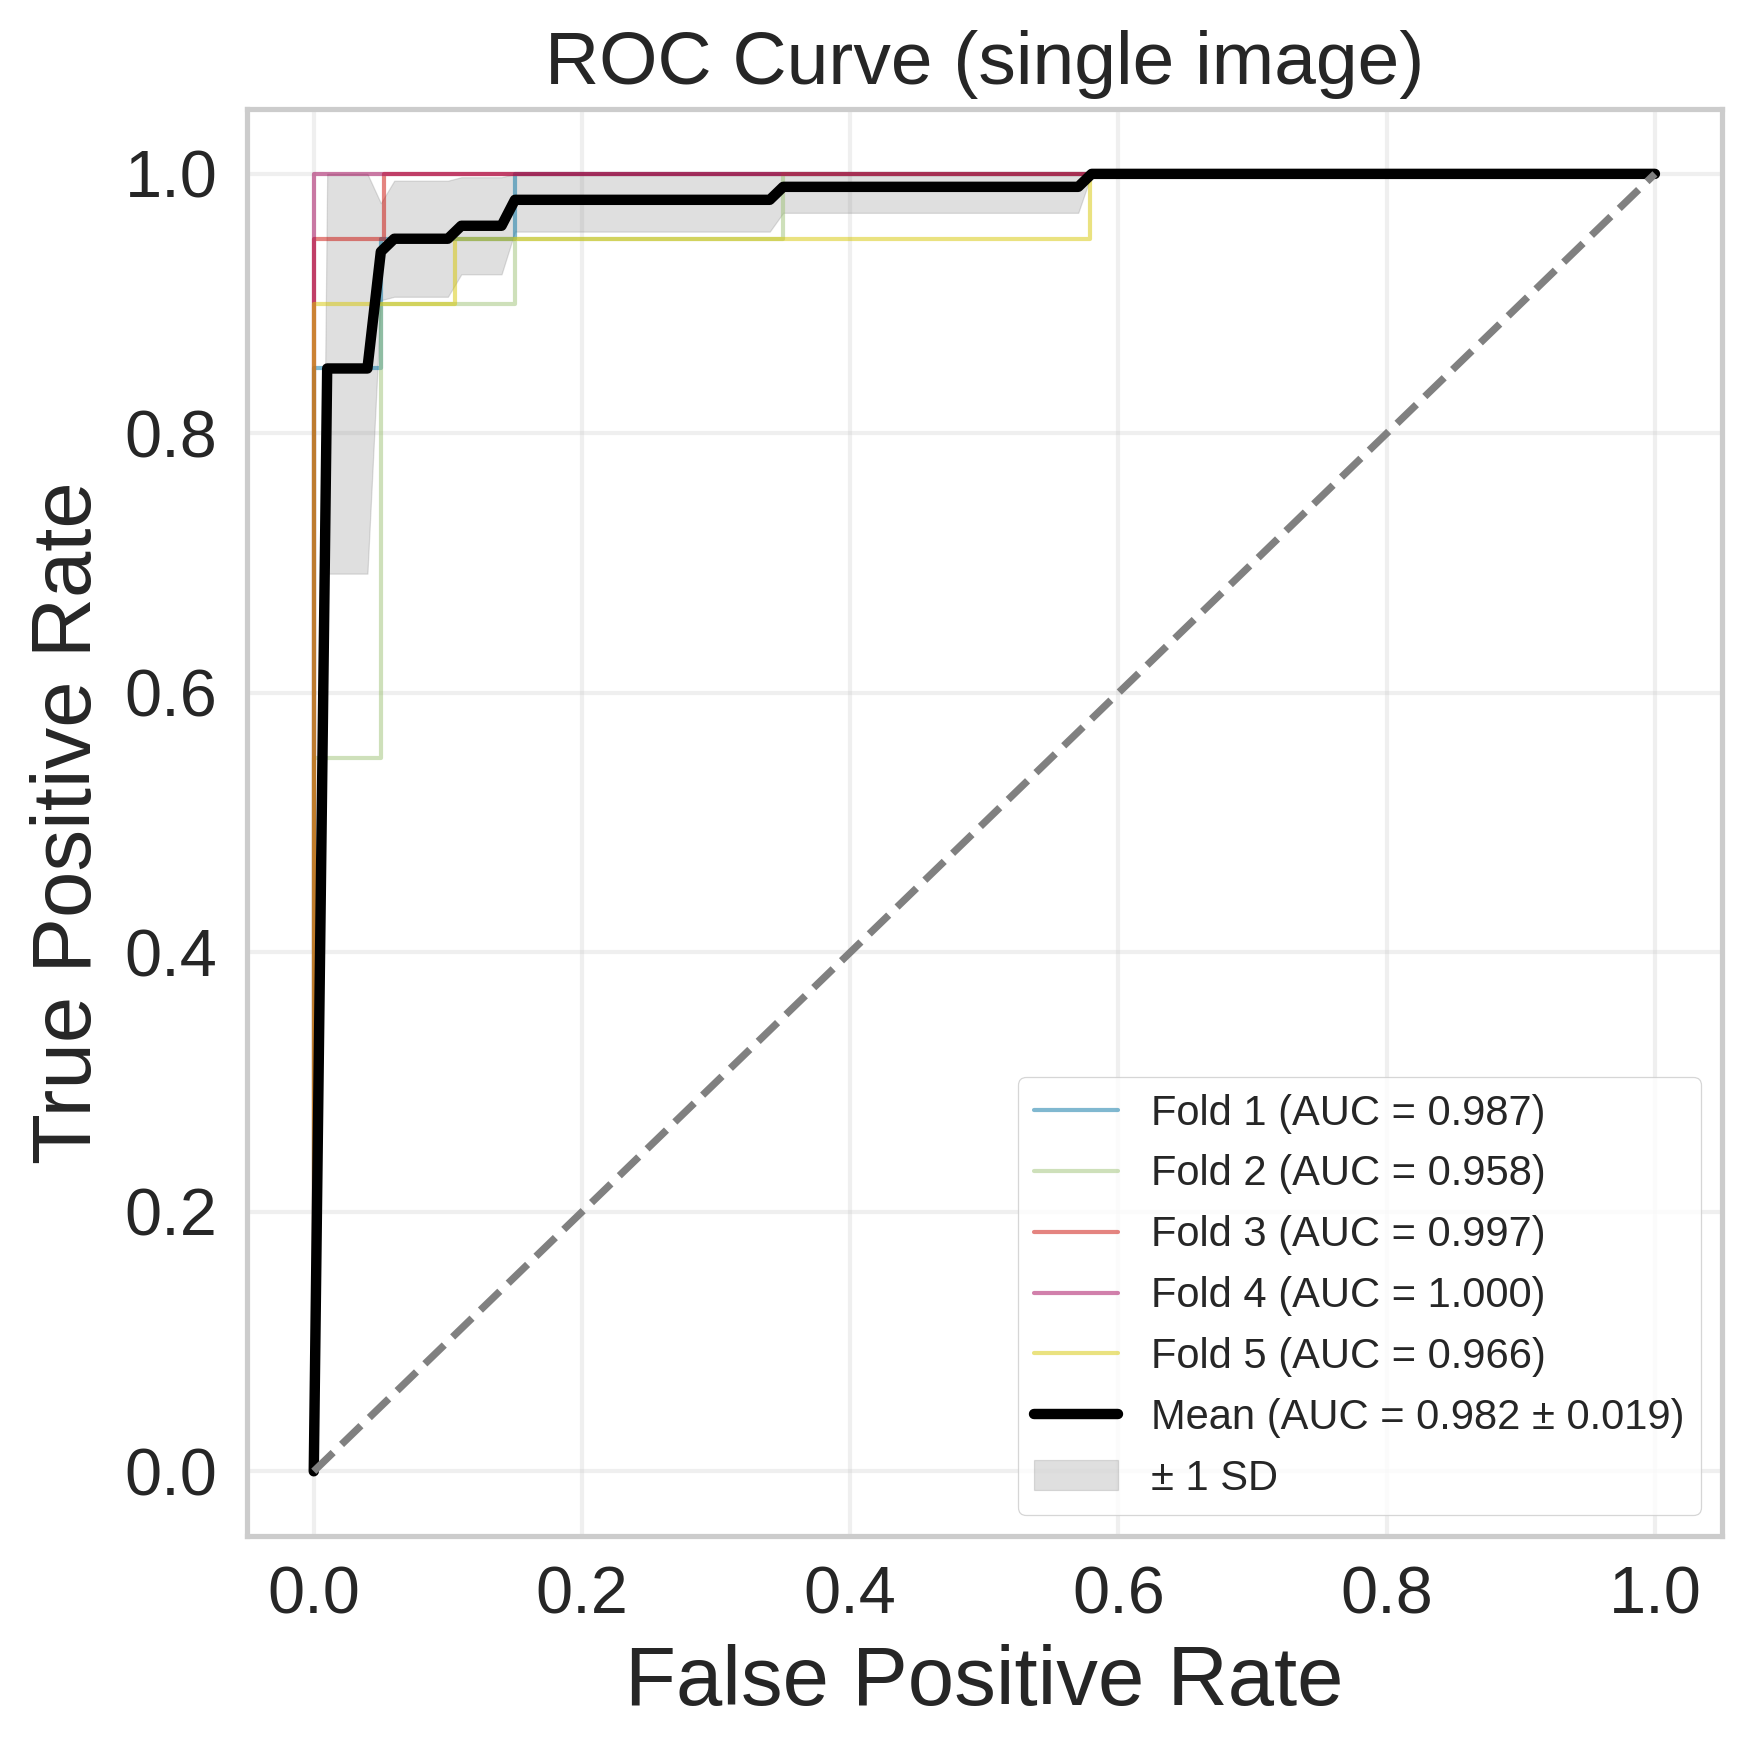

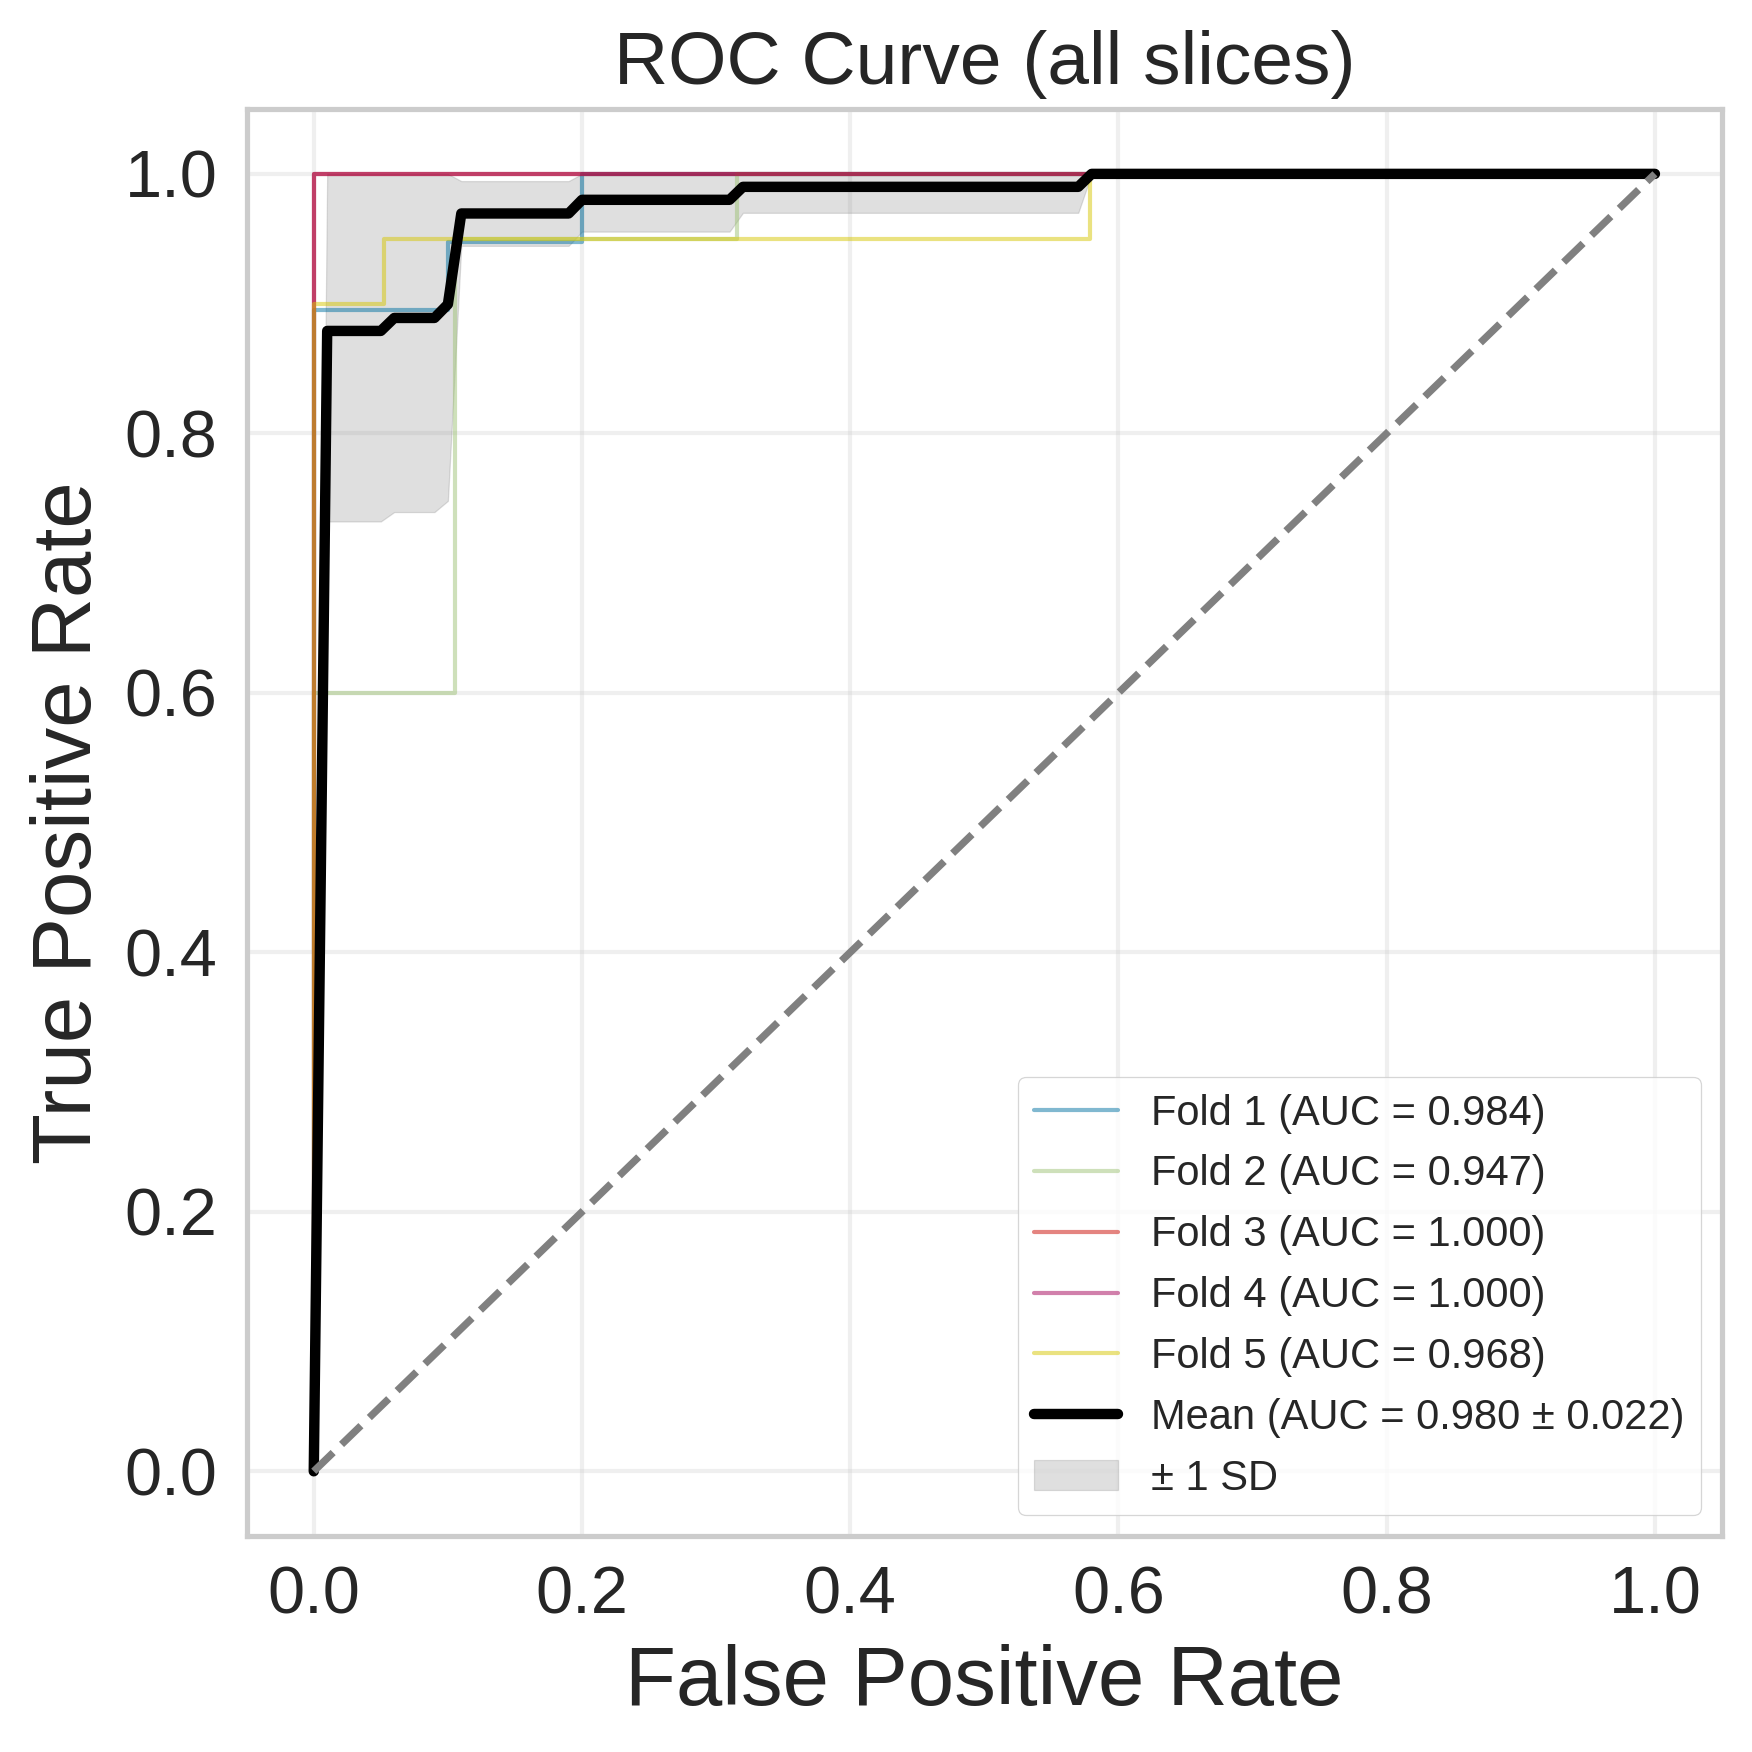

In [10]:
# ===== ROC curves: per fold (thin lines) + mean ROC ± 1 SD (thick line and band) =====
mean_fpr = np.linspace(0, 1, 101)

def plot_cv_roc(df, score_col, title, save_path):
    fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
    tprs, aucs = [], []
    for k in sorted(df["fold"].unique()):
        d = df[df["fold"] == k]
        fpr, tpr, _ = roc_curve(d["label_x"], d[score_col])
        auc_k = roc_auc_score(d["label_x"], d[score_col])
        ax.plot(fpr, tpr, linewidth=1, alpha=0.5, label=f"Fold {k} (AUC = {auc_k:.3f})")
        interp = np.interp(mean_fpr, fpr, tpr)
        interp[0] = 0.0
        tprs.append(interp)
        aucs.append(auc_k)

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    sd_tpr = np.std(tprs, axis=0)
    ax.plot(mean_fpr, mean_tpr, color="black", linewidth=2.5,
            label=f"Mean (AUC = {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f})")
    ax.fill_between(mean_fpr, np.clip(mean_tpr - sd_tpr, 0, 1), np.clip(mean_tpr + sd_tpr, 0, 1),
                    color="gray", alpha=0.25, label="± 1 SD")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set_xlabel("False Positive Rate", fontsize=20)
    ax.set_ylabel("True Positive Rate", fontsize=20)
    ax.set_title(title, fontsize=18)
    ax.tick_params(axis="both", labelsize=16)
    ax.legend(fontsize=10, loc="lower right", frameon=True)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_cv_roc(df_single, "prob", "ROC Curve (single image)", f"{OUT_DIR}/single_image_roc_cv.png")
plot_cv_roc(df_patient, "max_prob", "ROC Curve (all slices)", f"{OUT_DIR}/all_slices_any_positive_roc_cv.png")